# Financial Transaction Fraud Detector
## Notebook 04b - Model Evaluation & Evasion Testing

**Owner:** Mohamed Mahmoud  
**Role:** Model Evaluation & Evasion Testing  
**Course / University:** AI in Cybersecurity, Sohag University  
**Date:** 2026-11-24

**Goal.** Measure every model honestly on unseen test data, explain the accuracy trap, find which signals matter, and test whether simple attacker tricks fool the model.

**Inputs:** `data/processed/features.parquet`, `models/`, `reports/validation.json`

**Outputs:** `reports/metrics.json`, `reports/feature_importance.json`, `reports/evasion.json`, `reports/figures/04b_*.png`

Run the notebooks in order 01, 02, 03, 04a, 04b, 05; each one reads the files saved by the previous one.

## Setup
We load the features, the four trained models from notebook 04a and the thresholds chosen on validation.
Everything in this notebook is measured on the **test** period (the latest hours), which no model saw during
training or threshold selection.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, plotstyle

plotstyle.apply()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

In [2]:
import joblib
from sklearn.inspection import permutation_importance

from src import evasion as E
from src import explain as X
from src import features as F
from src import scoring as S
from src import train as T

feats = data.load_features()
meta = S.load_meta()
validation = data.read_json("validation.json")
models = joblib.load(data.PROCESSED / "comparison_models.joblib")
primary_name = meta["model"]
primary = S.load_model()
t1, t2 = meta["thresholds"]["review"], meta["thresholds"]["block"]

_, _, test = T.apply_split(feats, meta["split_steps"]["train_before"], meta["split_steps"]["test_from"])
y = test["isFraud"].to_numpy()
print(f"Test set: {len(test):,} rows, {int(y.sum()):,} fraud ({100 * y.mean():.2f}%)")
print(f"Primary model: {primary_name} ({meta['model_name']}); Review from {t1:.4f}, Block from {t2:.4f}")

Test set: 416,297 rows, 4,020 fraud (0.97%)
Primary model: P (Pre-transaction); Review from 0.9818, Block from 0.9945


## 1. The accuracy trap

**Accuracy** = share of all predictions that are correct. When fraud is rare, a "model" that simply says
**"never fraud"** is almost always right, yet it catches **zero** fraud. That is why we never judge a fraud
model by accuracy, and why claims of "99.9% accuracy" on this kind of data mean nothing on their own.

In [3]:
never = T.binary_metrics(y, np.zeros_like(y))
print(f'"Never fraud" accuracy: {100 * never["accuracy"]:.2f}%   fraud caught: {never["recall"]:.0%}')

"Never fraud" accuracy: 99.03%   fraud caught: 0%


## 2. Every model and baseline on the test set

To compare fairly, every model uses the threshold that caught 85% of fraud **on validation**
(from notebook 04a). The isFlaggedFraud rule has no threshold; it either flags or not.

- **Precision**: of the alerts, how many are real fraud.
- **Recall**: of the real fraud, how much we catch.
- **F1**: one number that balances precision and recall.
- **ROC-AUC / PR-AUC**: ranking quality over all thresholds (PR-AUC is the honest one for rare fraud).
- **Alerts per 1,000**: how many transactions the bank's team must look at.

In [4]:
labels = {
    "isFlaggedFraud rule": "Simulator rule",
    "LogReg (R features)": "Logistic Regression baseline",
    "R": "R: Realistic (no balances)",
    "P": "P: Pre-transaction balances",
    "L": "L: Leaky (uses leaked information, not real)",
}
rows = []
flag = test["isFlaggedFraud"].to_numpy()
rows.append({"model": "isFlaggedFraud rule", **T.binary_metrics(y, flag), "roc_auc": np.nan, "pr_auc": np.nan})
test_scores = {}
for name, model in models.items():
    p = model.predict_proba(test)[:, 1]
    test_scores[name] = p
    thr = validation["thresholds_at_85_recall"][name]
    rows.append({"model": name, **T.binary_metrics(y, p >= thr), **T.score_metrics(y, p)})
comparison = pd.DataFrame(rows).set_index("model")
show = comparison[["precision", "recall", "f1", "roc_auc", "pr_auc", "alerts_per_1000", "accuracy"]].copy()
show.index = [labels[i] for i in show.index]
show.style.format("{:.3f}", na_rep="-").format("{:.2f}", subset=["alerts_per_1000"])

,precision,recall,f1,roc_auc,pr_auc,alerts_per_1000,accuracy
Simulator rule,1.000,0.003,0.006,-,-,0.03,0.990
Logistic Regression baseline,0.020,0.939,0.039,0.888,0.165,451.48,0.557
R: Realistic (no balances),0.056,0.888,0.104,0.943,0.561,154.43,0.853
P: Pre-transaction balances,0.972,0.873,0.920,1.000,0.979,8.67,0.999
"L: Leaky (uses leaked information, not real)",1.000,0.973,0.986,1.000,1.000,9.40,1.000


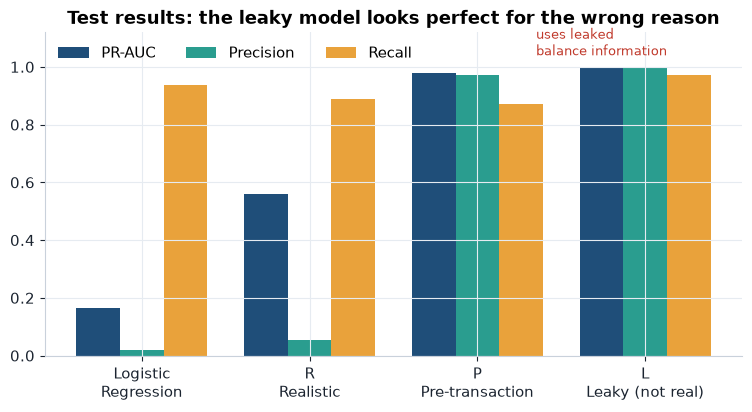

In [5]:
order = ["LogReg (R features)", "R", "P", "L"]
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(order))
w = 0.26
for i, (metric, color) in enumerate([("pr_auc", plotstyle.NAVY), ("precision", plotstyle.TEAL), ("recall", plotstyle.AMBER)]):
    vals = comparison.loc[order, metric].to_numpy()
    ax.bar(x + (i - 1) * w, vals, width=w, color=color, label={"pr_auc": "PR-AUC", "precision": "Precision", "recall": "Recall"}[metric])
ax.set_xticks(x, ["Logistic\nRegression", "R\nRealistic", "P\nPre-transaction", "L\nLeaky (not real)"])
ax.set_ylim(0, 1.12)
ax.set_title("Test results: the leaky model looks perfect for the wrong reason")
ax.legend(ncol=3, loc="upper left")
ax.annotate("uses leaked\nbalance information", xy=(3, 1.0), xytext=(2.35, 1.04), fontsize=9, color=plotstyle.RED)
plotstyle.save(fig, "04b_model_comparison")
plt.show()

**Reading the comparison.**
- **L** is almost perfect because it reads the balances **after** the transaction. In PaySim those balances are
  distorted for fraud rows (fraud was cancelled in the simulation), so the model learns the simulator, not fraud.
  This is why many published "99.9%" results on PaySim are misleading.
- **P** uses balances **before** the transaction, which a bank does know at approval time. Its strength comes
  mainly from one strong pattern: in PaySim, a fraudster almost always moves the **entire** balance. Real
  fraudsters are less predictable, so P's numbers are an **optimistic upper bound**.
- **R** uses no balances. Its result is the most cautious estimate of what the receiver-history idea alone achieves.

## 3. The primary model in detail

Now we use the primary model's real thresholds (Approve / Review / Block).

In [6]:
p_test = test_scores[primary_name]
verdict = np.where(p_test >= t2, "Block", np.where(p_test >= t1, "Review", "Approve"))
rb = T.binary_metrics(y, verdict != "Approve")
blk = T.binary_metrics(y, verdict == "Block")
scores = T.score_metrics(y, p_test)
print(f"PR-AUC {scores['pr_auc']:.3f}   ROC-AUC {scores['roc_auc']:.4f}")
print(f"Review or Block: precision {rb['precision']:.3f}, recall {rb['recall']:.3f}, F1 {rb['f1']:.3f}, "
      f"{rb['alerts_per_1000']:.2f} alerts per 1,000")
print(f"Block only:      precision {blk['precision']:.3f}, recall {blk['recall']:.3f}")
table = pd.crosstab(pd.Series(y).map({0: "Normal", 1: "Fraud"}).rename("actual"),
                    pd.Series(verdict).rename("verdict")).reindex(columns=["Approve", "Review", "Block"], fill_value=0)
table

PR-AUC 0.979   ROC-AUC 0.9998
Review or Block: precision 0.878, recall 0.936, F1 0.906, 10.30 alerts per 1,000
Block only:      precision 0.981, recall 0.859


verdict,Approve,Review,Block
actual,,,
Fraud,257,311,3452
Normal,411753,456,68


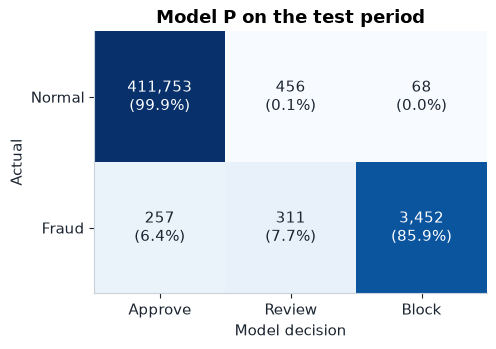

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
vals = table.loc[["Normal", "Fraud"]].to_numpy()
share = vals / vals.sum(axis=1, keepdims=True)
ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(3):
        ax.text(j, i, f"{vals[i, j]:,}\n({100 * share[i, j]:.1f}%)", ha="center", va="center",
                color="white" if share[i, j] > 0.5 else plotstyle.INK, fontsize=11)
ax.set_xticks(range(3), ["Approve", "Review", "Block"])
ax.set_yticks(range(2), ["Normal", "Fraud"])
ax.set_xlabel("Model decision")
ax.set_ylabel("Actual")
ax.grid(False)
ax.set_title(f"Model {primary_name} on the test period")
plotstyle.save(fig, "04b_confusion_matrix")
plt.show()

## 4. Which signals does the model rely on? (permutation importance)

We shuffle one feature at a time and measure how much PR-AUC drops. A big drop means the model depends on
that feature. To keep it fast we use all test fraud rows plus a random 40,000 normal rows.

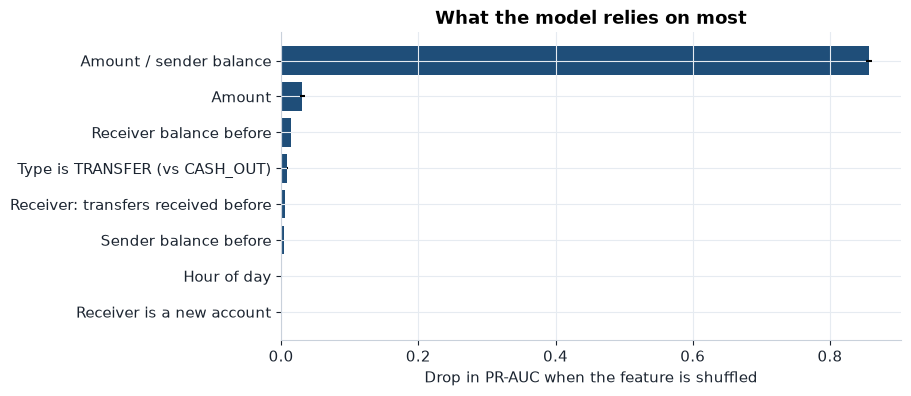

,label,importance,std
0,Amount / sender balance,0.86,0.00
1,Amount,0.03,0.00
2,Receiver balance before,0.01,0.00
3,Type is TRANSFER (vs CASH_OUT),0.01,0.00
4,Receiver: transfers received before,0.01,0.00
5,Sender balance before,0.00,0.00
6,Hour of day,0.00,0.00
7,Receiver is a new account,0.00,0.00


In [8]:
sub = pd.concat([test[test["isFraud"] == 1], test[test["isFraud"] == 0].sample(40_000, random_state=1)])
pi = permutation_importance(primary, sub[meta["features"]], sub["isFraud"], scoring="average_precision",
                            n_repeats=5, random_state=0, n_jobs=1)
imp = (pd.DataFrame({"feature": meta["features"], "importance": pi.importances_mean, "std": pi.importances_std})
       .sort_values("importance", ascending=False).reset_index(drop=True))
imp["label"] = imp["feature"].map(F.FEATURE_LABELS)

top = imp.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top["label"], top["importance"], xerr=top["std"], color=plotstyle.NAVY)
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.set_title("What the model relies on most")
plotstyle.save(fig, "04b_feature_importance")
plt.show()
imp[["label", "importance", "std"]].head(8)

## 5. Warning signs in plain English

`src/explain.py` turns the features into short **warning signs** that a bank employee can read, such as
"Money goes to a brand-new receiver account". These are simple rules on the same features, shown in the app
under the title **"Warning signs found"**. They are a helpful summary, **not** the model's exact reasoning.

In [9]:
sub_signs = pd.concat([test[test["isFraud"] == 1], test[test["isFraud"] == 0].sample(20_000, random_state=2)])
signs = sub_signs.apply(lambda r: X.warning_signs(r, use_balances=meta["uses_balances"]), axis=1)
all_signs = sorted({s for lst in signs for s in lst})
freq = pd.DataFrame({
    "Fraud (%)": [100 * signs[sub_signs["isFraud"] == 1].apply(lambda l: s in l).mean() for s in all_signs],
    "Normal (%)": [100 * signs[sub_signs["isFraud"] == 0].apply(lambda l: s in l).mean() for s in all_signs],
}, index=all_signs).sort_values("Fraud (%)", ascending=False)
freq.style.format("{:.1f}")

,Fraud (%),Normal (%)
The transaction empties the whole balance of the sender.,97.2,0.1
Money goes to a brand-new receiver account (no earlier incoming transfers).,63.4,14.7
Receiver account shows a zero balance before the transfer.,50.0,2.3
"Very large amount (1,000,000 or more).",29.3,4.6
"Unusual hour (night, 00:00 to 05:59).",25.7,1.4
"Amount is at the 10,000,000 maximum that large frauds are split into.",4.9,0.0
Receiver got many transfers before (possible collection or mule account).,3.5,11.1
Receiver got another transfer in the last few hours.,0.9,11.6


In [10]:
example = test[(test["isFraud"] == 1) & (verdict == "Block")].iloc[0]
print(f"Example fraud: {('TRANSFER' if example['is_transfer'] else 'CASH_OUT')} of {example['amount']:,.0f} at hour {int(example['hour'])}")
for s in X.warning_signs(example, use_balances=meta["uses_balances"]):
    print(" -", s)

Example fraud: TRANSFER of 2,344,540 at hour 17
 - Money goes to a brand-new receiver account (no earlier incoming transfers).
 - Very large amount (1,000,000 or more).
 - The transaction empties the whole balance of the sender.
 - Receiver account shows a zero balance before the transfer.


## 6. Evasion test: can a smart attacker slip through?

We take **100 fraud transactions from the test period that the model catches** (Review or Block) and change
**one thing at a time**, as an attacker would. Then we count how many drop to **Approve**.

| Trick | What changes |
|---|---|
| Split the amount | Send 3 to 5 smaller transfers instead of one. Counted as a success only if **every** piece is approved. |
| Receiver with history | Use an older account with typical history instead of a brand-new mule. |
| Daytime hour | Do it at 14:00 instead of at night. |
| Round amount | Use a round number (rounded down to 1,000). |

In [11]:
caught = test[(test["isFraud"] == 1) & (verdict != "Approve")]
base = caught.sample(100, random_state=11)
features = meta["features"]

def decide(rows):
    p = primary.predict_proba(rows[features])[:, 1]
    return np.where(p >= t2, "Block", np.where(p >= t1, "Review", "Approve"))

normal_hist = test[(test["isFraud"] == 0) & (test["recv_is_new"] == 0)]
typical = {"count": float(normal_hist["recv_count_before"].median()),
           "total": float(normal_hist["recv_total_before"].median()),
           "hours": float(normal_hist["recv_hours_since_last"].median())}

results = {}
pieces, owner = E.split_amount(base, seed=3)
piece_verdicts = pd.Series(decide(pieces))
all_approved = piece_verdicts.groupby(owner).apply(lambda v: (v == "Approve").all())
some_approved = piece_verdicts.groupby(owner).apply(lambda v: (v == "Approve").any())
results["split_amount"] = {"pct_approved": float(100 * all_approved.mean()),
                           "pct_some_pieces_approved": float(100 * some_approved.mean())}
for key, changed in [
    ("receiver_with_history", E.receiver_with_history(base, typical["count"], typical["total"], typical["hours"])),
    ("daytime_hour", E.daytime_hour(base)),
    ("round_amount", E.round_amount(base)),
]:
    results[key] = {"pct_approved": float(100 * (decide(changed) == "Approve").mean())}

ev = pd.DataFrame([{"trick": E.TRICKS[k], "fraud that now slips through (%)": v["pct_approved"]} for k, v in results.items()])
print(f"Typical receiver used for the second trick: {typical['count']:.0f} earlier transfers, last one {typical['hours']:.0f} hours ago")
ev

Typical receiver used for the second trick: 6 earlier transfers, last one 50 hours ago


,trick,fraud that now slips through (%)
0,Split the amount into 3 to 5 smaller transfers,91.00
1,Use a receiver account with normal history ins...,30.00
2,Move the transfer to a daytime hour (14:00),6.00
3,"Use a round, normal-looking amount (rounded do...",3.00


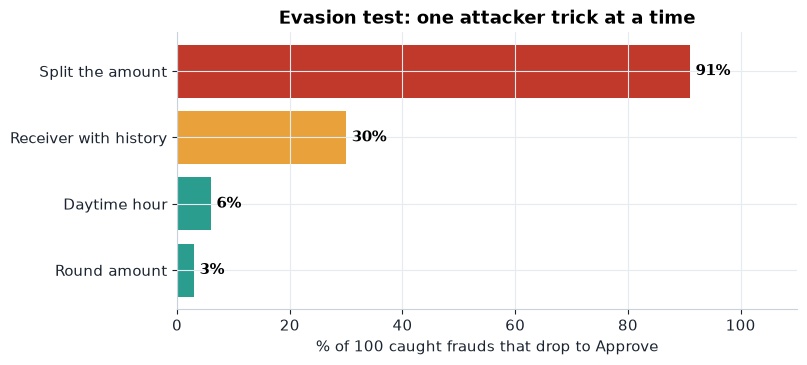

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
short = ["Split the amount", "Receiver with history", "Daytime hour", "Round amount"]
vals = [results[k]["pct_approved"] for k in E.TRICKS]
bars = ax.barh(short[::-1], vals[::-1], color=[plotstyle.RED if v >= 50 else plotstyle.AMBER if v >= 10 else plotstyle.TEAL for v in vals[::-1]])
for b, v in zip(bars, vals[::-1]):
    ax.text(v + 1, b.get_y() + b.get_height() / 2, f"{v:.0f}%", va="center", fontweight="bold")
ax.set_xlim(0, 110)
ax.set_xlabel("% of 100 caught frauds that drop to Approve")
ax.set_title("Evasion test: one attacker trick at a time")
plotstyle.save(fig, "04b_evasion")
plt.show()

**What the evasion test tells us.** Tricks that change the **pattern the model relies on** work best. If the
attacker no longer empties the account in one go (splitting the amount), the strongest signal disappears.
Changing only the hour or rounding the amount barely helps the attacker. A real system would add rules that
look at **several transactions together** (for example, many transfers from one account in a short time).

In [13]:
verdict_counts = {k: {c: int(v) for c, v in table.loc[k].items()} for k in ["Normal", "Fraud"]}
metrics = {
    "test_rows": int(len(test)),
    "test_fraud": int(y.sum()),
    "test_fraud_rate_pct": float(100 * y.mean()),
    "test_steps": f"{meta['split_steps']['test_from']}-743",
    "accuracy_trap": {"never_fraud_accuracy": never["accuracy"], "never_fraud_recall": never["recall"]},
    "primary": {
        "model": primary_name,
        "model_name": meta["model_name"],
        "thresholds": meta["thresholds"],
        **scores,
        "review_or_block": rb,
        "block": blk,
        "verdict_counts": verdict_counts,
    },
    "comparison": [
        {"model": k, "label": labels[k], **{m: (None if pd.isna(comparison.loc[k, m]) else float(comparison.loc[k, m]))
                                             for m in ["precision", "recall", "f1", "roc_auc", "pr_auc", "alerts_per_1000", "accuracy"]}}
        for k in ["isFlaggedFraud rule", "LogReg (R features)", "R", "P", "L"]
    ],
    "random_split_check": validation["random_split_check"],
}
data.write_json(metrics, data.REPORTS / "metrics.json")
data.write_json({"model": primary_name, "scoring": "average_precision",
                 "features": imp[["feature", "label", "importance", "std"]].to_dict(orient="records")},
                data.REPORTS / "feature_importance.json")
data.write_json({"n_frauds": 100, "selection": "random fraud rows from the test period that the model catches (Review or Block)",
                 "typical_receiver": typical,
                 "tricks": {k: {"description": E.TRICKS[k], **v} for k, v in results.items()},
                 "warning_sign_frequency_pct": {s: {"fraud": float(r["Fraud (%)"]), "normal": float(r["Normal (%)"])} for s, r in freq.iterrows()}},
                data.REPORTS / "evasion.json")
print("Saved reports/metrics.json, reports/feature_importance.json, reports/evasion.json")

Saved reports/metrics.json, reports/feature_importance.json, reports/evasion.json


In [14]:
cmp = comparison
data.write_findings("04b_evaluation_and_evasion", [
    f'The accuracy trap: always answering "not fraud" scores {100 * never["accuracy"]:.2f}% accuracy on the test period and catches no fraud at all.',
    f"Primary model {primary_name} on the test period: catches {100 * rb['recall']:.1f}% of fraud at Review or Block with {100 * rb['precision']:.1f}% precision and {rb['alerts_per_1000']:.1f} alerts per 1,000 transactions (PR-AUC {scores['pr_auc']:.3f}).",
    f"Test PR-AUC by model: R {cmp.loc['R', 'pr_auc']:.3f}, P {cmp.loc['P', 'pr_auc']:.3f}, L {cmp.loc['L', 'pr_auc']:.3f} (leaky, not real), Logistic Regression {cmp.loc['LogReg (R features)', 'pr_auc']:.3f}; the isFlaggedFraud rule catches {100 * cmp.loc['isFlaggedFraud rule', 'recall']:.2f}% of fraud.",
    f"Top signals for model {primary_name}: {', '.join(imp['label'].head(3).str.lower())}.",
    f"Evasion: splitting the amount lets {results['split_amount']['pct_approved']:.0f}% of caught frauds through; a receiver with history {results['receiver_with_history']['pct_approved']:.0f}%; a daytime hour {results['daytime_hour']['pct_approved']:.0f}%; a round amount {results['round_amount']['pct_approved']:.0f}%.",
])
print("Findings saved.")

Findings saved.


## Key findings

- The accuracy trap: always answering "not fraud" scores 99.03% accuracy on the test period and catches no fraud at all.
- Primary model P on the test period: catches 93.6% of fraud at Review or Block with 87.8% precision and 10.3 alerts per 1,000 transactions (PR-AUC 0.979).
- Test PR-AUC by model: R 0.561, P 0.979, L 1.000 (leaky, not real), Logistic Regression 0.165; the isFlaggedFraud rule catches 0.32% of fraud.
- Top signals for model P: amount / sender balance, amount, receiver balance before.
- Evasion: splitting the amount lets 91% of caught frauds through; a receiver with history 30%; a daytime hour 6%; a round amount 3%.